# ML-10 — Content Action Playbook

[Open this notebook in Colab](https://colab.research.google.com/github/Sai875/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb)

This notebook turns the validated Week 6 ranking into a **human-reviewed action queue**. It uses a client-grouped holdout: the model is trained on one set of clients and ranks pages from held-out clients. The queue is an educational decision-support artifact, not a production system.

**Evidence boundary:** the label is an observed decline proxy from one snapshot. A high score means “review this page sooner,” not “this page will decline in the future” or “refreshing it will improve performance.”

## Setup — load the same starter data and build the validated ranking

The features deliberately exclude `trend_direction`, `trend_pct`, identifiers, and any recommendation-derived fields. A client-grouped split keeps each `client_id` on only one side of the evaluation.

In [1]:
import sys
import os
import json
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
REPO_URL = "https://github.com/Sai875/flyrank-ml-internship.git"
REPO_DIR = Path("/content/flyrank-ml-internship")
DATA_PATH = Path("data/raw/content_refresh_anonymized.csv")

# In Colab, use the repository copy when available; otherwise download the public starter CSV.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
    os.chdir(REPO_DIR)
else:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / DATA_PATH).exists():
            os.chdir(candidate)
            break

DATA_PATH = Path("data/raw/content_refresh_anonymized.csv")
if not DATA_PATH.exists():
    try:
        from huggingface_hub import hf_hub_download
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
        from huggingface_hub import hf_hub_download

    downloaded = hf_hub_download(
        repo_id="FlyRank/internship-starter",
        repo_type="dataset",
        filename="content_refresh_anonymized.csv",
    )
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    import shutil
    shutil.copy2(downloaded, DATA_PATH)

df = pd.read_csv(DATA_PATH)
required = {"trend_direction", "client_id", "avg_position", "days_since_last_update",
            "impressions_90d", "ctr", "content_type"}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f"Required columns missing from dataset: {missing}")

df["is_declining_label"] = df["trend_direction"].astype(str).str.lower().eq("down").astype(int)
df["days_since_last_update"] = pd.to_numeric(df["days_since_last_update"], errors="coerce")
df["impressions_90d"] = pd.to_numeric(df["impressions_90d"], errors="coerce")
df["ctr"] = pd.to_numeric(df["ctr"], errors="coerce")
df["avg_position_raw"] = pd.to_numeric(df["avg_position"], errors="coerce")
df["avg_position_no_data"] = df["avg_position_raw"].fillna(0).eq(0).astype(int)
df["avg_position_model"] = df["avg_position_raw"].replace(0, np.nan)

NUMERIC = ["days_since_last_update", "impressions_90d", "ctr",
           "avg_position_model", "avg_position_no_data"]
CATEGORICAL = ["content_type"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "is_declining_label"

forbidden = {"trend_direction", "trend_pct", TARGET, "content_id", "client_id"}
assert not (set(FEATURES) & forbidden), f"Forbidden feature(s): {set(FEATURES) & forbidden}"

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("cat", categorical_pipe, CATEGORICAL),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("logreg", LogisticRegression(max_iter=1000, random_state=SEED)),
])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, y=df[TARGET], groups=df["client_id"]))
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()
assert set(train_df["client_id"].astype(str)).isdisjoint(set(test_df["client_id"].astype(str)))

model.fit(train_df[FEATURES], train_df[TARGET])
test_df["review_score"] = model.predict_proba(test_df[FEATURES])[:, 1]

def precision_at_k(y_true, scores, k=50):
    order = np.argsort(-np.asarray(scores), kind="mergesort")[:min(k, len(scores))]
    return float(np.asarray(y_true)[order].mean())

base_rate = float(test_df[TARGET].mean())
p50 = precision_at_k(test_df[TARGET], test_df["review_score"], 50)
lift50 = p50 / base_rate if base_rate > 0 else float("nan")
metrics = {
    "seed": SEED,
    "split": "client-grouped holdout",
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "client_overlap": int(len(set(train_df["client_id"].astype(str)) & set(test_df["client_id"].astype(str)))),
    "test_base_rate": base_rate,
    "precision_at_50": p50,
    "lift_at_50": lift50,
    "roc_auc": float(roc_auc_score(test_df[TARGET], test_df["review_score"])),
    "average_precision": float(average_precision_score(test_df[TARGET], test_df["review_score"])),
}
print("Grouped-holdout validation receipts")
display(pd.DataFrame([metrics]).round(3))
print("Note: this score ranks an observed label proxy; it is not a future-outcome forecast.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


content_refresh_anonymized.csv:   0%|          | 0.00/8.23M [00:00<?, ?B/s]

Grouped-holdout validation receipts


,seed,split,train_rows,test_rows,client_overlap,test_base_rate,precision_at_50,lift_at_50,roc_auc,average_precision
0,42,client-grouped holdout,23837,6163,0,0.511,0.62,1.213,0.563,0.555


Note: this score ranks an observed label proxy; it is not a future-outcome forecast.


## 1. Ranked actions + reason codes

The queue is sorted by model score within held-out clients. Reason codes are transparent checks based on page signals; they are **not explanations of the model’s internal reasoning**. Thresholds below are simple triage heuristics and should be reviewed against business context.

Decay/refresh insight: older content can be a useful review cue, but age alone does not prove content decay or justify a refresh. First verify accuracy, intent, demand, and whether the page has a meaningful improvement opportunity.

In [2]:
# Heuristic cutoffs are explicit and easy to change after editorial review.
positive_impressions = test_df.loc[test_df["impressions_90d"].gt(0), "impressions_90d"]
positive_ctr = test_df.loc[test_df["impressions_90d"].gt(0), "ctr"]
impressions_cut = float(positive_impressions.median()) if len(positive_impressions) else 0.0
ctr_cut = float(positive_ctr.median()) if len(positive_ctr) else 0.0

def reason_codes(row):
    codes = []
    if pd.isna(row["avg_position_model"]):
        codes.append("NO_POSITION_DATA")
    elif row["avg_position_model"] >= 20:
        codes.append("LOW_VISIBILITY")
    if pd.notna(row["ctr"]) and row["impressions_90d"] > 0 and row["ctr"] < ctr_cut:
        codes.append("LOW_CTR")
    if pd.notna(row["impressions_90d"]) and row["impressions_90d"] > 0 and row["impressions_90d"] < impressions_cut:
        codes.append("LOW_DEMAND_OR_REACH")
    if pd.notna(row["days_since_last_update"]) and row["days_since_last_update"] >= 180:
        codes.append("STALE_CONTENT_CANDIDATE")
    if not codes:
        codes.append("GENERAL_REVIEW")
    return codes

def action_for(codes):
    codes = set(codes)
    if "NO_POSITION_DATA" in codes:
        return ("VERIFY_MEASUREMENT", "Check indexing, tracking, and reporting before editing content.")
    if "LOW_CTR" in codes:
        return ("SNIPPET_AND_INTENT_REVIEW", "Review title/snippet accuracy, search intent, and SERP context; do not promise a CTR gain.")
    if "LOW_VISIBILITY" in codes and "STALE_CONTENT_CANDIDATE" in codes:
        return ("CONTENT_REFRESH_ASSESSMENT", "Fact-check the page, compare current intent, and inspect internal links before proposing a refresh.")
    if "LOW_VISIBILITY" in codes:
        return ("VISIBILITY_DIAGNOSIS", "Review query fit, indexing, competition, and internal links before changing the page.")
    if "LOW_DEMAND_OR_REACH" in codes:
        return ("DEMAND_AND_INDEXATION_CHECK", "Check seasonality, demand, and indexation before investing in a rewrite.")
    if "STALE_CONTENT_CANDIDATE" in codes:
        return ("FRESHNESS_REVIEW", "Check for outdated facts and changed intent; age alone is not a refresh decision.")
    return ("EDITORIAL_TRIAGE", "A human should inspect the page and decide whether any action is warranted.")

test_df["reason_codes"] = test_df.apply(reason_codes, axis=1)
actions = test_df["reason_codes"].apply(action_for)
test_df["action_code"] = actions.apply(lambda x: x[0])
test_df["suggested_action"] = actions.apply(lambda x: x[1])

# Queue tiers are capacity-planning labels, not probabilities of recovery.
ranked = test_df.sort_values("review_score", ascending=False, kind="mergesort").copy()
n = len(ranked)
ranked["rank"] = np.arange(1, n + 1)
ranked["priority_tier"] = np.where(ranked["rank"] <= max(1, int(np.ceil(0.10*n))), "HIGH",
                           np.where(ranked["rank"] <= max(1, int(np.ceil(0.30*n))), "MEDIUM", "MONITOR"))

id_cols = [c for c in ["content_id", "client_id", "content_type"] if c in ranked.columns]
queue = ranked[id_cols].copy()
queue["rank"] = ranked["rank"].to_numpy()
queue["review_score"] = ranked["review_score"].to_numpy().round(4)
queue["priority_tier"] = ranked["priority_tier"].to_numpy()
queue["reason_codes"] = ranked["reason_codes"].apply(lambda xs: ";".join(xs)).to_numpy()
queue["action_code"] = ranked["action_code"].to_numpy()
queue["suggested_action"] = ranked["suggested_action"].to_numpy()
queue["days_since_last_update"] = ranked["days_since_last_update"].to_numpy()
queue["impressions_90d"] = ranked["impressions_90d"].to_numpy()
queue["ctr"] = ranked["ctr"].to_numpy()
queue["avg_position"] = ranked["avg_position_raw"].to_numpy()

display(queue.head(20))
print(f"Review queue rows: {len(queue):,}; ranked only on held-out clients.")
print("The queue omits the target label so it can be read as a review artifact, not as an outcome guarantee.")

,content_id,client_id,content_type,rank,review_score,priority_tier,reason_codes,action_code,suggested_action,days_since_last_update,impressions_90d,ctr,avg_position
7027,content_d983fb4ec74f,client_8527a891e2,keyword article,1,0.6977,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,98,0.00,0.5
19205,content_17c2de35424d,client_8527a891e2,keyword article,2,0.6957,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",103,3,0.00,1.0
7256,content_bc4411bf8d9f,client_8527a891e2,keyword article,3,0.6945,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,24,0.00,1.6
4213,content_9b28cf5ae4f3,client_f369cb89fc,keyword article,4,0.6940,HIGH,GENERAL_REVIEW,EDITORIAL_TRIAGE,A human should inspect the page and decide whe...,106,1620,0.06,1.1
5377,content_fb4884e34467,client_4e07408562,keyword article,5,0.6939,HIGH,LOW_CTR,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,580,0.00,1.5
27709,content_84c5f6af423c,client_8527a891e2,keyword article,6,0.6936,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,8,0.00,1.9
10809,content_a138ab3bd14d,client_4e07408562,keyword article,7,0.6933,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,200,0.00,1.9
28216,content_4a147f223b0b,client_4e07408562,keyword article,8,0.6931,HIGH,GENERAL_REVIEW,EDITORIAL_TRIAGE,A human should inspect the page and decide whe...,104,491,0.20,0.9
24004,content_cc6c749bcdf2,client_8527a891e2,keyword article,9,0.6927,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,5,0.00,2.2
11770,content_aa0a0e791d47,client_8527a891e2,keyword article,10,0.6923,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",103,17,0.00,2.1


Review queue rows: 6,163; ranked only on held-out clients.
The queue omits the target label so it can be read as a review artifact, not as an outcome guarantee.


### Archetype → action mapping

| Archetype / reason code | First human check | Candidate action (only if verified) |
|---|---|---|
| `NO_POSITION_DATA` | Check reporting, indexation, and whether search data exists | Fix measurement or investigate indexation before editing |
| `LOW_CTR` | Compare query intent, title/snippet, and current SERP | Test a truthful snippet/title revision |
| `LOW_VISIBILITY` + stale candidate | Fact accuracy, intent match, internal links, competing pages | Prepare a scoped content refresh proposal |
| `LOW_VISIBILITY` alone | Indexing, competition, intent, site architecture | Diagnose before rewriting |
| `LOW_DEMAND_OR_REACH` | Seasonality, demand, indexation, page purpose | Defer or monitor if demand is naturally low |
| `STALE_CONTENT_CANDIDATE` alone | Check if facts or user needs changed | Update only specific outdated sections |
| `GENERAL_REVIEW` | Editorial and analytics context | No action unless a reviewer finds a concrete issue |

Reason codes are intentionally multi-label. A page can have more than one review cue; the human reviewer decides which, if any, matters.

## 2. Intended use and limits

**Intended user:** an SEO analyst or editor who needs a manageable first-pass review list.

**Intended use:** use the ranking to decide which held-out pages to inspect first, then use the reason codes to start a structured diagnosis. Keep the queue small enough for a real reviewer to verify.

**Limits:** the dataset is an anonymized snapshot; the label is an observed decline proxy. The result does not establish future decline, explain Google’s algorithm, establish causation, or show that a refresh will recover performance. Model scores are ranking signals, not calibrated business value or probabilities of success. The queue is based on a grouped holdout for evaluation and is a research artifact, not a production service.

In [3]:
intended_use_check = pd.DataFrame([
    {"question": "Who uses it?", "answer": "SEO analyst/editor conducting manual triage"},
    {"question": "What does a high score mean?", "answer": "Review earlier for the observed decline proxy"},
    {"question": "What does it not mean?", "answer": "Not future certainty, causation, or a promise of recovery"},
    {"question": "What is the unit of decision?", "answer": "One pseudonymized content item; client_id is for grouping only"},
    {"question": "Where should it run?", "answer": "Offline research notebook / non-production workflow"},
])
display(intended_use_check)

,question,answer
0,Who uses it?,SEO analyst/editor conducting manual triage
1,What does a high score mean?,Review earlier for the observed decline proxy
2,What does it not mean?,"Not future certainty, causation, or a promise ..."
3,What is the unit of decision?,One pseudonymized content item; client_id is f...
4,Where should it run?,Offline research notebook / non-production wor...


## 3. Human review + the no-go list

Before action, a reviewer should verify the page identity, current facts, search intent, indexation/measurement, seasonality, competing pages, and whether a change has a clear success measure. Record the decision and rationale; “no change” is a valid outcome.

**Do not automate:** publishing or rewriting pages; changing titles/meta descriptions; deleting, redirecting, or canonicalizing URLs; changing internal links at scale; making claims about ranking guarantees; or allocating budget based only on this score. Do not expose client names, private queries, or URLs in shared notebook outputs. Pseudonymous IDs are only for authorized internal matching.

In [4]:
review_checklist = pd.DataFrame([
    {"review_step": "Confirm the correct page and data freshness", "required": True},
    {"review_step": "Check measurement/indexation and missing data", "required": True},
    {"review_step": "Verify current facts and search intent", "required": True},
    {"review_step": "Check seasonality, demand, and competing pages", "required": True},
    {"review_step": "Write a proposed change and success metric", "required": True},
    {"review_step": "Human approves, defers, or rejects the action", "required": True},
])
no_go = [
    "Auto-publish or auto-rewrite content",
    "Auto-change URLs, redirects, canonicals, or site-wide links",
    "Promise ranking/traffic recovery from a refresh",
    "Treat score as a causal explanation or future certainty",
    "Use trend_direction, trend_pct, IDs, or prior recommendation fields as model features",
]
display(review_checklist)
print("NO-GO CASES")
for item in no_go:
    print(" -", item)

,review_step,required
0,Confirm the correct page and data freshness,True
1,Check measurement/indexation and missing data,True
2,Verify current facts and search intent,True
3,"Check seasonality, demand, and competing pages",True
4,Write a proposed change and success metric,True
5,"Human approves, defers, or rejects the action",True


NO-GO CASES
 - Auto-publish or auto-rewrite content
 - Auto-change URLs, redirects, canonicals, or site-wide links
 - Promise ranking/traffic recovery from a refresh
 - Treat score as a causal explanation or future certainty
 - Use trend_direction, trend_pct, IDs, or prior recommendation fields as model features


## 4. Monitoring / retrain triggers

Start with a monthly review while this is a small research prototype. Keep a simple record of reviewer decisions and outcomes so the next evaluation can test usefulness rather than merely reproduce the same snapshot.

Suggested triggers:
- **Re-evaluate before reuse** if the source schema, label definition, or measurement pipeline changes.
- **Investigate drift** if missingness in key inputs rises by 10 percentage points, or if the top reason-code mix changes sharply between review cycles.
- **Revisit the model** if grouped-holdout Precision@50 falls to or below the base rate (lift at or below 1.0) on a fresh, properly defined evaluation set for two consecutive checks.
- **Retrain only with new, appropriately timed data and a fresh grouped/time-aware evaluation**; do not retrain just to improve a number on the same snapshot.
- Record the model version, dataset date, metrics, and human override rate for each review cycle.

In [5]:
monitoring_triggers = pd.DataFrame([
    {"signal": "Input missingness", "trigger": "Increase of >=10 percentage points", "response": "Check collection/measurement; pause use if unresolved"},
    {"signal": "Reason-code mix", "trigger": "Large month-to-month shift", "response": "Inspect dataset mix and threshold behavior"},
    {"signal": "Grouped Precision@50", "trigger": "Lift <=1.0 for two fresh checks", "response": "Suspend prioritization claim and investigate"},
    {"signal": "Schema / label / tracking change", "trigger": "Any material change", "response": "Rebuild features and revalidate before reuse"},
    {"signal": "New labeled data", "trigger": "Enough new periods/clients for a fresh split", "response": "Evaluate retraining against a simple baseline"},
])
display(monitoring_triggers)

,signal,trigger,response
0,Input missingness,Increase of >=10 percentage points,Check collection/measurement; pause use if unr...
1,Reason-code mix,Large month-to-month shift,Inspect dataset mix and threshold behavior
2,Grouped Precision@50,Lift <=1.0 for two fresh checks,Suspend prioritization claim and investigate
3,Schema / label / tracking change,Any material change,Rebuild features and revalidate before reuse
4,New labeled data,Enough new periods/clients for a fresh split,Evaluate retraining against a simple baseline


## Cost / value thinking

Use a small pilot rather than a broad rollout. Estimate reviewer minutes per page, the number of pages the team can realistically inspect, and the value of a correct diagnosis. Compare the ranked queue with a simple baseline (for example, the same review capacity chosen by a transparent freshness rule). A model is useful only if it helps reviewers find worthwhile cases with less effort or better consistency.

Do not claim monetary ROI until review time, action cost, and observed outcomes have been measured. A page that receives no change after review is not necessarily a failure: the queue may have helped rule out unnecessary work.

In [6]:
# Editable planning assumptions only — replace with measured team values before claiming ROI.
review_capacity_pages = 50
minutes_per_review = 15
hourly_reviewer_cost = 25.0  # currency units per hour; illustrative assumption, not an observed cost
estimated_hours = review_capacity_pages * minutes_per_review / 60
estimated_review_cost = estimated_hours * hourly_reviewer_cost

cost_value = pd.DataFrame([{
    "review_capacity_pages": review_capacity_pages,
    "minutes_per_review_assumed": minutes_per_review,
    "estimated_reviewer_hours": round(estimated_hours, 2),
    "hourly_cost_assumed": hourly_reviewer_cost,
    "estimated_review_cost_assumed": round(estimated_review_cost, 2),
    "interpretation": "Planning scenario only; not measured ROI or expected recovery value",
}])
display(cost_value)

,review_capacity_pages,minutes_per_review_assumed,estimated_reviewer_hours,hourly_cost_assumed,estimated_review_cost_assumed,interpretation
0,50,15,12.5,25.0,312.5,Planning scenario only; not measured ROI or ex...


## 5. Exports for the paper

The ranked queue CSV is generated in `work/outputs/` and should stay out of Git as instructed by the assignment’s leak guard. The summary metrics JSON and the reusable figure are written separately so they can be reviewed and committed if permitted by the repository rules. Do not include the decline label in the queue export.

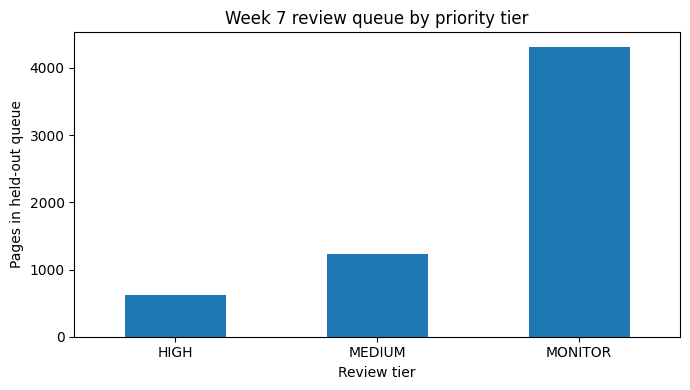

Generated files:
  Queue CSV (keep out of Git): work/outputs/w07_ranked_action_queue.csv
  Metrics JSON (review Git rules before committing): work/outputs/w07_playbook_metrics.json
  Figure for paper: work/figures/w07_priority_tiers.png

Queue preview:


,content_id,client_id,content_type,rank,review_score,priority_tier,reason_codes,action_code,suggested_action,days_since_last_update,impressions_90d,ctr,avg_position
7027,content_d983fb4ec74f,client_8527a891e2,keyword article,1,0.6977,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,98,0.00,0.5
19205,content_17c2de35424d,client_8527a891e2,keyword article,2,0.6957,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",103,3,0.00,1.0
7256,content_bc4411bf8d9f,client_8527a891e2,keyword article,3,0.6945,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,24,0.00,1.6
4213,content_9b28cf5ae4f3,client_f369cb89fc,keyword article,4,0.6940,HIGH,GENERAL_REVIEW,EDITORIAL_TRIAGE,A human should inspect the page and decide whe...,106,1620,0.06,1.1
5377,content_fb4884e34467,client_4e07408562,keyword article,5,0.6939,HIGH,LOW_CTR,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,580,0.00,1.5
27709,content_84c5f6af423c,client_8527a891e2,keyword article,6,0.6936,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,8,0.00,1.9
10809,content_a138ab3bd14d,client_4e07408562,keyword article,7,0.6933,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,200,0.00,1.9
28216,content_4a147f223b0b,client_4e07408562,keyword article,8,0.6931,HIGH,GENERAL_REVIEW,EDITORIAL_TRIAGE,A human should inspect the page and decide whe...,104,491,0.20,0.9
24004,content_cc6c749bcdf2,client_8527a891e2,keyword article,9,0.6927,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",104,5,0.00,2.2
11770,content_aa0a0e791d47,client_8527a891e2,keyword article,10,0.6923,HIGH,LOW_CTR;LOW_DEMAND_OR_REACH,SNIPPET_AND_INTENT_REVIEW,"Review title/snippet accuracy, search intent, ...",103,17,0.00,2.1


In [7]:
OUTPUT_DIR = Path("work/outputs")
FIGURE_DIR = Path("work/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"
metrics_path = OUTPUT_DIR / "w07_playbook_metrics.json"
figure_path = FIGURE_DIR / "w07_priority_tiers.png"

queue.to_csv(queue_path, index=False)
with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

tier_counts = queue["priority_tier"].value_counts().reindex(["HIGH", "MEDIUM", "MONITOR"], fill_value=0)
plt.figure(figsize=(7, 4))
tier_counts.plot(kind="bar")
plt.title("Week 7 review queue by priority tier")
plt.xlabel("Review tier")
plt.ylabel("Pages in held-out queue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("Generated files:")
print(f"  Queue CSV (keep out of Git): {queue_path}")
print(f"  Metrics JSON (review Git rules before committing): {metrics_path}")
print(f"  Figure for paper: {figure_path}")
print("\nQueue preview:")
display(queue.head(10))

## 6. Self-check

Before submission, verify that the notebook runs from a fresh runtime, the grouped split has zero client overlap, the exported queue contains no target label, and all claims remain directional. The queue CSV must not be committed. Commit the notebook and any figure/metrics artifact that the repository rules allow, then submit your public repository URL.

In [8]:
checks = {
    "zero client overlap": metrics["client_overlap"] == 0,
    "forbidden features excluded": not (set(FEATURES) & forbidden),
    "queue is ranked": queue["rank"].is_monotonic_increasing,
    "target omitted from queue": TARGET not in queue.columns,
    "queue has reason codes": queue["reason_codes"].notna().all(),
    "exports created": queue_path.exists() and metrics_path.exists() and figure_path.exists(),
}
for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
assert all(checks.values()), "One or more self-checks failed; fix them before submitting."
print("\nSelf-check passed. Still run Runtime → Run all from a fresh Colab session before submission.")

[PASS] zero client overlap
[PASS] forbidden features excluded
[PASS] queue is ranked
[PASS] target omitted from queue
[PASS] queue has reason codes
[PASS] exports created

Self-check passed. Still run Runtime → Run all from a fresh Colab session before submission.
